# Lab 1: Data Visualization, Preprocessing, and Statistical Analysis

Name: Sandip Sitaula<br>
Course: MSCS 634 – Advanced Big Data and Data Mining<br>
Assignment: Lab 1 – Data Visualization, Data Preprocessing, and Statistical Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Step 1: Data Collection

I used the Warehouse and Retail Sales dataset from Data.gov. It is published by Montgomery County, Maryland, and is free to use (public domain).

- Data.gov page: https://catalog.data.gov/dataset/warehouse-and-retail-sales
- Downloaded on October 26, 2026, and saved as data/warehouse_retail_sales.csv


In [2]:
df = pd.read_csv("data/warehouse_retail_sales.csv")

# Make one date column from YEAR and MONTH (used for the line plot)
df["DATE"] = pd.to_datetime(df["YEAR"].astype(str) + "-" + df["MONTH"].astype(str) + "-01")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (341037, 10)


,YEAR,MONTH,SUPPLIER,ITEM CODE,ITEM DESCRIPTION,ITEM TYPE,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES,DATE
0,2020,1,REPUBLIC NATIONAL DISTRIBUTING CO,100009,BOOTLEG RED - 750ML,WINE,0.00,0.0,2.0,2020-01-01
1,2020,1,PWSWN INC,100024,MOMENT DE PLAISIR - 750ML,WINE,0.00,1.0,4.0,2020-01-01
2,2020,1,RELIABLE CHURCHILL LLLP,1001,S SMITH ORGANIC PEAR CIDER - 18.7OZ,BEER,0.00,0.0,1.0,2020-01-01
3,2020,1,LANTERNA DISTRIBUTORS INC,100145,SCHLINK HAUS KABINETT - 750ML,WINE,0.00,0.0,1.0,2020-01-01
4,2020,1,DIONYSOS IMPORTS INC,100293,SANTORINI GAVALA WHITE - 750ML,WINE,0.82,0.0,0.0,2020-01-01


## Step 2: Data Visualization

### 2.1 Scatter plot: retail transfers vs. retail sales

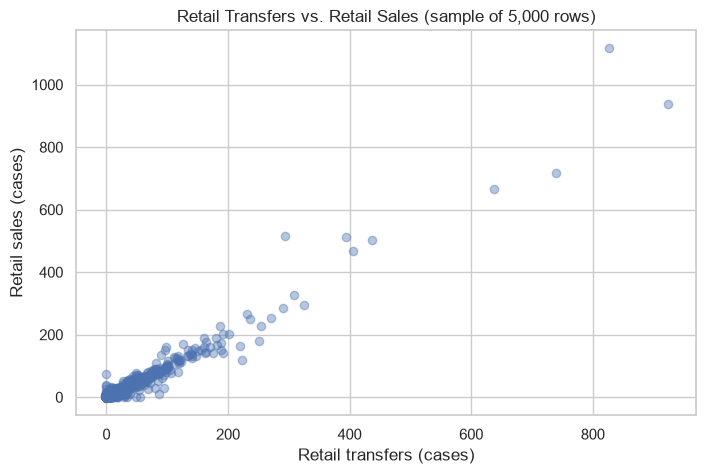

Correlation: 0.93


In [3]:
# The data has 341,000 rows, so I plot a random sample of 5,000 rows to keep it readable
sample = df.sample(n=5000, random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(sample["RETAIL TRANSFERS"], sample["RETAIL SALES"], alpha=0.4)
plt.title("Retail Transfers vs. Retail Sales (sample of 5,000 rows)")
plt.xlabel("Retail transfers (cases)")
plt.ylabel("Retail sales (cases)")
plt.show()

print("Correlation:", round(df["RETAIL SALES"].corr(df["RETAIL TRANSFERS"]), 2))

The points follow a straight line going up. When a store sells more cases of a product, the warehouse also sends it more cases. The correlation is 0.93, which is very strong. One exception in the full data is ICE: it sells up to 2,923 cases a month but has zero transfers, so the stores probably get ice from somewhere other than the county warehouse.

### 2.2 Line plot: total retail sales by month

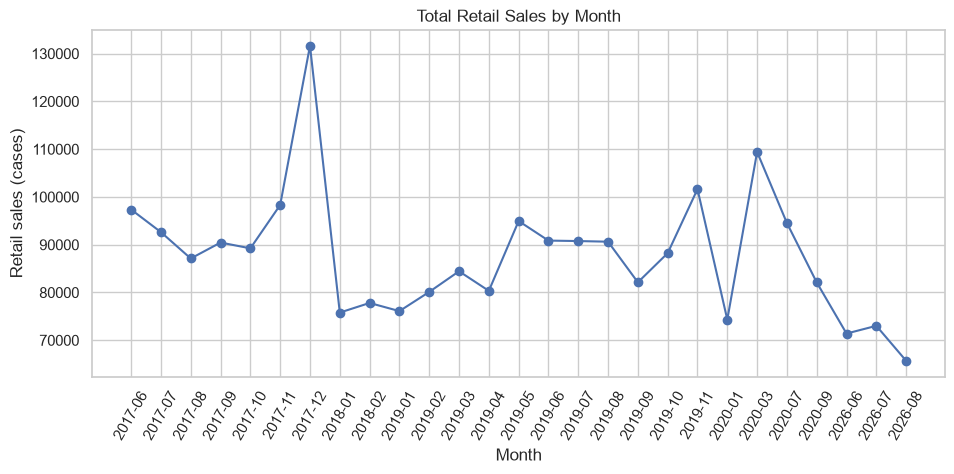

Number of months in the data: 27
Top 3 months:
DATE
2017-12-01    131634.49
2020-03-01    109411.29
2019-11-01    101631.31
Name: RETAIL SALES, dtype: float64


In [4]:
monthly_sales = df.groupby("DATE")["RETAIL SALES"].sum()

plt.figure(figsize=(11, 4.5))
plt.plot(monthly_sales.index.strftime("%Y-%m"), monthly_sales.values, marker="o")
plt.title("Total Retail Sales by Month")
plt.xlabel("Month")
plt.ylabel("Retail sales (cases)")
plt.xticks(rotation=60)
plt.show()

print("Number of months in the data:", len(monthly_sales))
print("Top 3 months:")
print(monthly_sales.sort_values(ascending=False).head(3))

Sales are usually between 75,000 and 100,000 cases a month. The highest month is December 2017 (131,634 cases), because people buy more during the holidays. March 2020 is the second highest (109,411 cases), probably because people stocked up at the start of COVID-19. Note: the data is missing many months (for example, March to December 2018 and October 2020 to May 2026), so the line jumps between months that are not next to each other.

### 2.3 Bar chart: retail sales vs. warehouse sales by item type

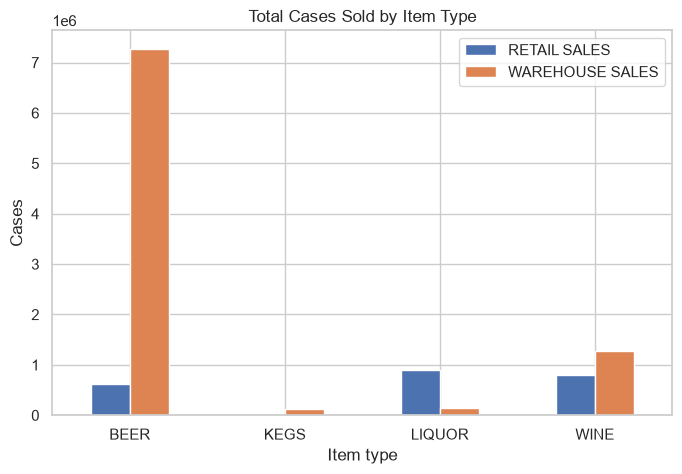

,RETAIL SALES,WAREHOUSE SALES
ITEM TYPE,,
BEER,620281.39,7276934.84
KEGS,0.00,129770.00
LIQUOR,904926.38,144278.89
WINE,794368.38,1275877.49


In [5]:
main_types = ["WINE", "LIQUOR", "BEER", "KEGS"]
main_df = df[df["ITEM TYPE"].isin(main_types)]
totals = main_df.groupby("ITEM TYPE")[["RETAIL SALES", "WAREHOUSE SALES"]].sum()

totals.plot(kind="bar", figsize=(8, 5), rot=0)
plt.title("Total Cases Sold by Item Type")
plt.xlabel("Item type")
plt.ylabel("Cases")
plt.show()

totals

Stores and the warehouse sell different things. In the stores, liquor sells the most (904,926 cases), then wine (794,368), then beer (620,281). From the warehouse, beer is far ahead with about 7.3 million cases, because bars and restaurants buy a lot of beer. Kegs are only sold from the warehouse, not in stores.

### 2.4 Histogram: how retail sales are distributed

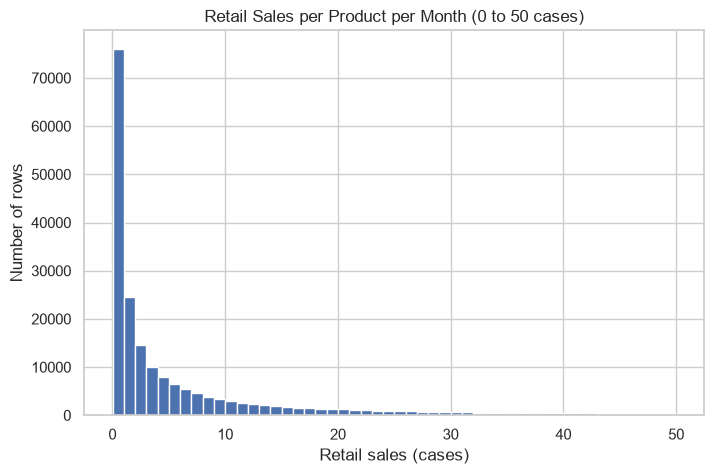

Rows with zero sales: 40.3 %
Mean: 6.95
Median: 0.25


In [6]:
# Most values are very small, so I only plot rows with sales between 0 and 50 cases
small_sales = df[(df["RETAIL SALES"] > 0) & (df["RETAIL SALES"] <= 50)]

plt.figure(figsize=(8, 5))
plt.hist(small_sales["RETAIL SALES"], bins=50)
plt.title("Retail Sales per Product per Month (0 to 50 cases)")
plt.xlabel("Retail sales (cases)")
plt.ylabel("Number of rows")
plt.show()

print("Rows with zero sales:", round((df["RETAIL SALES"] == 0).mean() * 100, 1), "%")
print("Mean:", round(df["RETAIL SALES"].mean(), 2))
print("Median:", df["RETAIL SALES"].median())

Most products sell only a small amount each month: the tallest bars are on the far left, between 0 and 1 case. 40.3% of rows have zero sales. The mean (6.95) is much bigger than the median (0.25), because a few products sell a lot and pull the mean up. This is called a right-skewed distribution.

### 2.5 Box plot: retail sales by item type

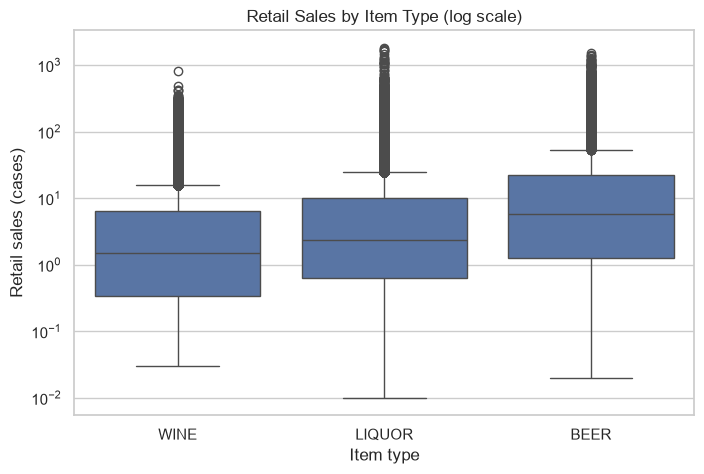

Median retail sales by item type:
ITEM TYPE
BEER      5.75
LIQUOR    2.38
WINE      1.48
Name: RETAIL SALES, dtype: float64


In [7]:
box_df = df[df["ITEM TYPE"].isin(["WINE", "LIQUOR", "BEER"]) & (df["RETAIL SALES"] > 0)]

plt.figure(figsize=(8, 5))
sns.boxplot(data=box_df, x="ITEM TYPE", y="RETAIL SALES")
plt.yscale("log")   # log scale, because a few products sell far more than the rest
plt.title("Retail Sales by Item Type (log scale)")
plt.xlabel("Item type")
plt.ylabel("Retail sales (cases)")
plt.show()

print("Median retail sales by item type:")
print(box_df.groupby("ITEM TYPE")["RETAIL SALES"].median())

Beer sells the most per product (median 5.75 cases a month), then liquor (2.38), then wine (1.48). The dots above each box are products that sell much more than usual. Wine has the lowest median even though it has the most products.

### 2.6 Pie chart: share of products by item type

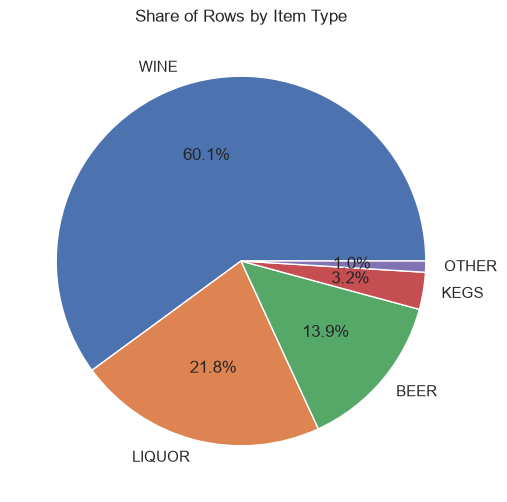

In [8]:
type_counts = df["ITEM TYPE"].value_counts()

# Keep the 4 biggest groups and combine the rest into "OTHER"
pie_data = type_counts.head(4)
pie_data["OTHER"] = type_counts.iloc[4:].sum()

plt.figure(figsize=(6, 6))
plt.pie(pie_data, labels=pie_data.index, autopct="%1.1f%%")
plt.title("Share of Rows by Item Type")
plt.show()

Wine makes up 60.1% of the rows, so most products in the catalog are wines. Liquor is 21.8% and beer is 13.9%. But the bar chart showed that liquor sells more cases in stores than wine. So having more products does not mean selling more.

## Step 3: Data Preprocessing

### 3.1 Handling missing values

In [9]:
print("Missing values in each column:")
df.isnull().sum()

Missing values in each column:


YEAR                  0
MONTH                 0
SUPPLIER            204
ITEM CODE             0
ITEM DESCRIPTION      0
ITEM TYPE             1
RETAIL SALES          6
RETAIL TRANSFERS      0
WAREHOUSE SALES       0
DATE                  0
dtype: int64

In [10]:
# Before: show the rows that have missing values (only product rows)
non_products = ["DUNNAGE", "REF", "STR_SUPPLIES"]
missing_rows = df[df.isnull().any(axis=1)]
missing_products = missing_rows[~missing_rows["ITEM TYPE"].isin(non_products)]

print("Rows with a missing value:", len(missing_rows))
print("Of these, product rows:", len(missing_products))
missing_products

Rows with a missing value: 205
Of these, product rows: 19


,YEAR,MONTH,SUPPLIER,ITEM CODE,ITEM DESCRIPTION,ITEM TYPE,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES,DATE
983,2020,1,NaN,2,ICE,NON-ALCOHOL,542.00,0.0,0.0,2020-01-01
12947,2020,7,NaN,2,ICE,NON-ALCOHOL,2739.00,0.0,0.0,2020-07-01
18396,2020,7,NaN,4,RMS ITEM,NON-ALCOHOL,NaN,0.0,0.0,2020-07-01
23237,2020,3,NaN,2,ICE,NON-ALCOHOL,561.00,0.0,0.0,2020-03-01
95667,2017,10,REPUBLIC NATIONAL DISTRIBUTING CO,347939,FONTANAFREDDA BAROLO SILVER LABEL 750 ML,NaN,0.00,0.0,1.0,2017-10-01
271338,2019,10,NaN,2,ICE,NON-ALCOHOL,854.00,0.0,0.0,2019-10-01
284426,2019,11,NaN,2,ICE,NON-ALCOHOL,793.00,0.0,0.0,2019-11-01
297374,2026,8,NaN,172000,STORE SPECIAL DISTRESSED RTD - 355ML,LIQUOR,36.72,0.0,0.0,2026-08-01
297782,2026,8,NaN,2,ICE,NON-ALCOHOL,2192.00,0.0,0.0,2026-08-01
302897,2026,8,NaN,4,RMS ITEM,NON-ALCOHOL,NaN,0.0,0.0,2026-08-01


How I handled each problem:

| Problem | What I did | Why |
|---|---|---|
| Rows that are not products (DUNNAGE = pallets, REF = refunds, STR_SUPPLIES = store supplies) | Dropped these rows | They are not real products, and most missing supplier names are in these rows. |
| RETAIL SALES is missing (6 rows) | Filled with 0 | These are placeholder rows ("RMS ITEM", "COUPON") with no sales activity. |
| ITEM TYPE is missing (1 row) | Filled with the mode (most common value) | The mode is WINE, and the product is a wine (a Barolo). |
| SUPPLIER is missing | Filled with "UNKNOWN" | We cannot guess the supplier, but the sales numbers in these rows are still useful. |

In [11]:
df_clean = df.copy()

# 1. Drop rows that are not products
df_clean = df_clean[~df_clean["ITEM TYPE"].isin(non_products)]

# 2. Fill missing retail sales with 0
df_clean["RETAIL SALES"] = df_clean["RETAIL SALES"].fillna(0)

# 3. Fill missing item type with the mode
most_common_type = df_clean["ITEM TYPE"].mode()[0]
df_clean["ITEM TYPE"] = df_clean["ITEM TYPE"].fillna(most_common_type)

# 4. Fill missing supplier with "UNKNOWN"
df_clean["SUPPLIER"] = df_clean["SUPPLIER"].fillna("UNKNOWN")

print("Rows before:", len(df), "| Rows after:", len(df_clean))
print("Missing values left:", df_clean.isnull().sum().sum())

# After: the same rows as before, now filled in
df_clean.loc[missing_products.index]

Rows before: 341037 | Rows after: 340327
Missing values left: 0


,YEAR,MONTH,SUPPLIER,ITEM CODE,ITEM DESCRIPTION,ITEM TYPE,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES,DATE
983,2020,1,UNKNOWN,2,ICE,NON-ALCOHOL,542.00,0.0,0.0,2020-01-01
12947,2020,7,UNKNOWN,2,ICE,NON-ALCOHOL,2739.00,0.0,0.0,2020-07-01
18396,2020,7,UNKNOWN,4,RMS ITEM,NON-ALCOHOL,0.00,0.0,0.0,2020-07-01
23237,2020,3,UNKNOWN,2,ICE,NON-ALCOHOL,561.00,0.0,0.0,2020-03-01
95667,2017,10,REPUBLIC NATIONAL DISTRIBUTING CO,347939,FONTANAFREDDA BAROLO SILVER LABEL 750 ML,WINE,0.00,0.0,1.0,2017-10-01
271338,2019,10,UNKNOWN,2,ICE,NON-ALCOHOL,854.00,0.0,0.0,2019-10-01
284426,2019,11,UNKNOWN,2,ICE,NON-ALCOHOL,793.00,0.0,0.0,2019-11-01
297374,2026,8,UNKNOWN,172000,STORE SPECIAL DISTRESSED RTD - 355ML,LIQUOR,36.72,0.0,0.0,2026-08-01
297782,2026,8,UNKNOWN,2,ICE,NON-ALCOHOL,2192.00,0.0,0.0,2026-08-01
302897,2026,8,UNKNOWN,4,RMS ITEM,NON-ALCOHOL,0.00,0.0,0.0,2026-08-01


### 3.2 Outlier detection and removal (IQR method)

Step A: First I try the normal IQR rule on RETAIL SALES.

In [12]:
Q1 = df_clean["RETAIL SALES"].quantile(0.25)
Q3 = df_clean["RETAIL SALES"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", round(IQR, 2))
print("Lower bound =", round(lower, 2))
print("Upper bound =", round(upper, 2))

outliers_normal = df_clean[(df_clean["RETAIL SALES"] < lower) | (df_clean["RETAIL SALES"] > upper)]
print("Outliers found:", len(outliers_normal))

Q1 = 0.0
Q3 = 3.27
IQR = 3.27
Lower bound = -4.9
Upper bound = 8.18
Outliers found: 52970


The normal rule finds 52,970 outliers (15.6% of the data). That is too many. About 40% of rows have zero sales, so Q1 is 0 and Q3 is very small. Any product selling more than about 8 cases a month counts as an "outlier", which would delete most popular products.

Step B: Sales data has a few very large values. A common fix is to apply the IQR rule to the log of the sales. The log shrinks big numbers, so the rule only catches values that are truly extreme. I only use rows with sales above 0, because the log of 0 cannot be taken in a useful way.

In [13]:
positive_sales = df_clean[df_clean["RETAIL SALES"] > 0]["RETAIL SALES"]
log_sales = np.log(positive_sales)

Q1_log = log_sales.quantile(0.25)
Q3_log = log_sales.quantile(0.75)
IQR_log = Q3_log - Q1_log
upper_log = Q3_log + 1.5 * IQR_log

# Change the upper bound back from log to cases
upper_cases = np.exp(upper_log)

print("Q1 (log) =", round(Q1_log, 3))
print("Q3 (log) =", round(Q3_log, 3))
print("IQR (log) =", round(IQR_log, 3))
print("Upper bound =", round(upper_cases, 2), "cases")

outliers = df_clean[df_clean["RETAIL SALES"] > upper_cases]
print("Outliers found:", len(outliers))

Q1 (log) = -0.693
Q3 (log) = 2.171
IQR (log) = 2.864
Upper bound = 644.23 cases
Outliers found: 122


In [14]:
print("Outliers by item type:")
print(outliers["ITEM TYPE"].value_counts())

print("\nThe 10 biggest outliers:")
outliers.sort_values("RETAIL SALES", ascending=False)[["DATE", "ITEM DESCRIPTION", "ITEM TYPE", "RETAIL SALES"]].head(10)

Outliers by item type:
ITEM TYPE
BEER           85
LIQUOR         29
NON-ALCOHOL     7
WINE            1
Name: count, dtype: int64

The 10 biggest outliers:


,DATE,ITEM DESCRIPTION,ITEM TYPE,RETAIL SALES
331469,2026-07-01,ICE,NON-ALCOHOL,2923.00
12947,2020-07-01,ICE,NON-ALCOHOL,2739.00
319915,2026-06-01,ICE,NON-ALCOHOL,2666.00
297782,2026-08-01,ICE,NON-ALCOHOL,2192.00
31182,2020-03-01,TITO'S HANDMADE VODKA - 1.75L,LIQUOR,1816.49
254051,2019-08-01,TITO'S HANDMADE VODKA - 1.75L,LIQUOR,1752.45
229213,2019-06-01,TITO'S HANDMADE VODKA - 1.75L,LIQUOR,1710.80
127249,2017-12-01,TITO'S HANDMADE VODKA - 1.75L,LIQUOR,1616.60
281697,2019-10-01,TITO'S HANDMADE VODKA - 1.75L,LIQUOR,1615.23
222110,2019-06-01,CORONA EXTRA LOOSE NR - 12OZ,BEER,1494.00


In [15]:
df_no_out = df_clean[df_clean["RETAIL SALES"] <= upper_cases]

print("Rows before removing outliers:", len(df_clean))
print("Rows after removing outliers:", len(df_no_out))
print("Biggest retail sales before:", df_clean["RETAIL SALES"].max())
print("Biggest retail sales after:", df_no_out["RETAIL SALES"].max())
df_no_out.head()

Rows before removing outliers: 340327
Rows after removing outliers: 340205
Biggest retail sales before: 2923.0
Biggest retail sales after: 643.48


,YEAR,MONTH,SUPPLIER,ITEM CODE,ITEM DESCRIPTION,ITEM TYPE,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES,DATE
0,2020,1,REPUBLIC NATIONAL DISTRIBUTING CO,100009,BOOTLEG RED - 750ML,WINE,0.00,0.0,2.0,2020-01-01
1,2020,1,PWSWN INC,100024,MOMENT DE PLAISIR - 750ML,WINE,0.00,1.0,4.0,2020-01-01
2,2020,1,RELIABLE CHURCHILL LLLP,1001,S SMITH ORGANIC PEAR CIDER - 18.7OZ,BEER,0.00,0.0,1.0,2020-01-01
3,2020,1,LANTERNA DISTRIBUTORS INC,100145,SCHLINK HAUS KABINETT - 750ML,WINE,0.00,0.0,1.0,2020-01-01
4,2020,1,DIONYSOS IMPORTS INC,100293,SANTORINI GAVALA WHITE - 750ML,WINE,0.82,0.0,0.0,2020-01-01


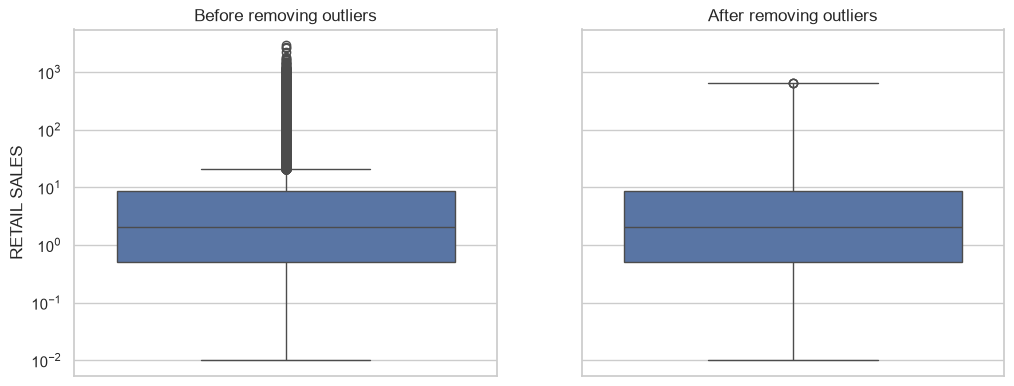

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

sns.boxplot(y=df_clean[df_clean["RETAIL SALES"] > 0]["RETAIL SALES"], ax=axes[0])
axes[0].set_title("Before removing outliers")
axes[0].set_yscale("log")

sns.boxplot(y=df_no_out[df_no_out["RETAIL SALES"] > 0]["RETAIL SALES"], ax=axes[1])
axes[1].set_title("After removing outliers")
axes[1].set_yscale("log")

plt.show()

With the log method, 122 rows (0.04% of the data) are outliers: anything above 644 cases in one month. These are the county's top sellers, such as ICE, Tito's vodka, and Corona beer. After removing them, the biggest monthly sale drops from 2,923 to 643 cases. These are real sales, not mistakes, but removing them makes the data better for describing a normal product.

### 3.3 Data reduction

In [17]:
print("Before reduction:", df_no_out.shape)
df_no_out.head(3)

Before reduction: (340205, 10)


,YEAR,MONTH,SUPPLIER,ITEM CODE,ITEM DESCRIPTION,ITEM TYPE,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES,DATE
0,2020,1,REPUBLIC NATIONAL DISTRIBUTING CO,100009,BOOTLEG RED - 750ML,WINE,0.0,0.0,2.0,2020-01-01
1,2020,1,PWSWN INC,100024,MOMENT DE PLAISIR - 750ML,WINE,0.0,1.0,4.0,2020-01-01
2,2020,1,RELIABLE CHURCHILL LLLP,1001,S SMITH ORGANIC PEAR CIDER - 18.7OZ,BEER,0.0,0.0,1.0,2020-01-01


In [18]:
# Sampling by number: pick 10,000 random rows
sample_number = df_no_out.sample(n=10000, random_state=42)
print("Sample by number:", sample_number.shape)

# Sampling by percentage: pick 10% of the rows
sample_percent = df_no_out.sample(frac=0.10, random_state=42)
print("Sample by percentage (10%):", sample_percent.shape)

# Dimension elimination: drop columns we do not need
# ITEM CODE and ITEM DESCRIPTION are just labels; YEAR and MONTH are already in DATE
reduced = sample_percent.drop(columns=["ITEM CODE", "ITEM DESCRIPTION", "YEAR", "MONTH"])
print("After dropping columns:", reduced.shape)
reduced.head()

Sample by number: (10000, 10)
Sample by percentage (10%): (34020, 10)
After dropping columns: (34020, 6)


,SUPPLIER,ITEM TYPE,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES,DATE
330850,PROXIMO SPIRITS INC,LIQUOR,3.74,2.0,1.0,2026-07-01
179180,DOPS INC,KEGS,0.00,0.0,1.0,2019-02-01
204985,E & J GALLO WINERY,LIQUOR,0.75,0.0,0.0,2019-04-01
272743,ANHEUSER BUSCH INC,BEER,500.00,475.0,1245.0,2019-10-01
57553,CONSTELLATION BRANDS,WINE,5.44,4.0,3.0,2017-07-01


The 10% sample is only used to show data reduction. In Step 4, I use the full cleaned data so the statistics are as accurate as possible.

### 3.4 Data scaling and discretization

In [19]:
scaled = df_no_out[["RETAIL SALES", "RETAIL TRANSFERS", "WAREHOUSE SALES"]].copy()
print("Before scaling:")
print(scaled.head())

# Min-Max scaling: (x - min) / (max - min), result is between 0 and 1
x = scaled["RETAIL SALES"]
scaled["RETAIL SALES (min-max)"] = (x - x.min()) / (x.max() - x.min())

# Z-score: (x - mean) / standard deviation
x = scaled["WAREHOUSE SALES"]
scaled["WAREHOUSE SALES (z-score)"] = (x - x.mean()) / x.std()

# Decimal scaling: divide by 1000 because the largest value (740) has 3 digits
scaled["RETAIL TRANSFERS (decimal)"] = scaled["RETAIL TRANSFERS"] / 1000

print("\nAfter scaling:")
scaled.head()

Before scaling:
   RETAIL SALES  RETAIL TRANSFERS  WAREHOUSE SALES
0          0.00               0.0              2.0
1          0.00               1.0              4.0
2          0.00               0.0              1.0
3          0.00               0.0              1.0
4          0.82               0.0              0.0

After scaling:


,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES,RETAIL SALES (min-max),WAREHOUSE SALES (z-score),RETAIL TRANSFERS (decimal)
0,0.00,0.0,2.0,0.009985,-0.109288,0.000
1,0.00,1.0,4.0,0.009985,-0.099384,0.001
2,0.00,0.0,1.0,0.009985,-0.114239,0.000
3,0.00,0.0,1.0,0.009985,-0.114239,0.000
4,0.82,0.0,0.0,0.011247,-0.119191,0.000


In [20]:
# Check the scaled columns
scaled[["RETAIL SALES (min-max)", "WAREHOUSE SALES (z-score)", "RETAIL TRANSFERS (decimal)"]].describe().round(3)

,RETAIL SALES (min-max),WAREHOUSE SALES (z-score),RETAIL TRANSFERS (decimal)
count,340205.000,340205.000,340205.000
mean,0.020,0.000,0.007
std,0.038,1.000,0.025
min,0.000,-1.255,-0.038
25%,0.010,-0.119,0.000
50%,0.010,-0.114,0.000
75%,0.015,-0.094,0.003
max,1.000,78.889,0.740


In [21]:
disc = df_no_out[["DATE", "MONTH", "ITEM TYPE", "RETAIL SALES"]].copy()
print("Before discretization:")
print(disc.head())

# Put retail sales into 4 groups
bins = [-100, 0, 1, 10, 1000]
labels = ["None", "Low", "Medium", "High"]
disc["SALES LEVEL"] = pd.cut(disc["RETAIL SALES"], bins=bins, labels=labels)

# Turn month numbers into seasons
seasons = {12: "Winter", 1: "Winter", 2: "Winter",
           3: "Spring", 4: "Spring", 5: "Spring",
           6: "Summer", 7: "Summer", 8: "Summer",
           9: "Fall", 10: "Fall", 11: "Fall"}
disc["SEASON"] = disc["MONTH"].map(seasons)

print("\nAfter discretization:")
print(disc.head())

print("\nRows in each sales level:")
print(disc["SALES LEVEL"].value_counts())

Before discretization:
        DATE  MONTH ITEM TYPE  RETAIL SALES
0 2020-01-01      1      WINE          0.00
1 2020-01-01      1      WINE          0.00
2 2020-01-01      1      BEER          0.00
3 2020-01-01      1      WINE          0.00
4 2020-01-01      1      WINE          0.82

After discretization:
        DATE  MONTH ITEM TYPE  RETAIL SALES SALES LEVEL  SEASON
0 2020-01-01      1      WINE          0.00        None  Winter
1 2020-01-01      1      WINE          0.00        None  Winter
2 2020-01-01      1      BEER          0.00        None  Winter
3 2020-01-01      1      WINE          0.00        None  Winter
4 2020-01-01      1      WINE          0.82         Low  Winter

Rows in each sales level:
SALES LEVEL
None      137201
Medium     80686
Low        75951
High       46367
Name: count, dtype: int64


Sales levels: None = 0 or less (no sale or a return), Low = more than 0 up to 1 case, Medium = more than 1 up to 10 cases, High = more than 10 cases.

## Step 4: Statistical Analysis

I use the cleaned data (df_no_out) for all statistics.

### 4.1 General overview

In [22]:
df_no_out.info()

<class 'pandas.DataFrame'>
Index: 340205 entries, 0 to 341035
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   YEAR              340205 non-null  int64         
 1   MONTH             340205 non-null  int64         
 2   SUPPLIER          340205 non-null  str           
 3   ITEM CODE         340205 non-null  str           
 4   ITEM DESCRIPTION  340205 non-null  str           
 5   ITEM TYPE         340205 non-null  str           
 6   RETAIL SALES      340205 non-null  float64       
 7   RETAIL TRANSFERS  340205 non-null  float64       
 8   WAREHOUSE SALES   340205 non-null  float64       
 9   DATE              340205 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(3), int64(2), str(4)
memory usage: 28.6 MB


In [23]:
df_no_out.describe()

,YEAR,MONTH,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES,DATE
count,340205.000000,340205.000000,340205.000000,340205.000000,340205.000000,340205
mean,2019.178348,6.479041,6.607873,6.582892,24.070332,2019-08-20 06:56:56.521215
min,2017.000000,1.000000,-6.490000,-38.490000,-229.330000,2017-06-01 00:00:00
25%,2017.000000,3.000000,0.000000,0.000000,0.000000,2017-12-01 00:00:00
50%,2019.000000,7.000000,0.250000,0.000000,1.000000,2019-04-01 00:00:00
75%,2019.000000,9.000000,3.250000,3.000000,5.000000,2019-11-01 00:00:00
max,2026.000000,12.000000,643.480000,740.000000,15955.460000,2026-08-01 00:00:00
std,2.471282,3.302331,24.394169,24.602204,201.947166,NaN


### 4.2 Central tendency

In [24]:
cols = ["RETAIL SALES", "RETAIL TRANSFERS", "WAREHOUSE SALES"]

for col in cols:
    print(col)
    print("  Minimum:", df_no_out[col].min())
    print("  Maximum:", df_no_out[col].max())
    print("  Mean:   ", round(df_no_out[col].mean(), 2))
    print("  Median: ", df_no_out[col].median())
    print("  Mode:   ", df_no_out[col].mode()[0])

RETAIL SALES
  Minimum: -6.49
  Maximum: 643.48
  Mean:    6.61
  Median:  0.25
  Mode:    0.0
RETAIL TRANSFERS
  Minimum: -38.49
  Maximum: 740.0
  Mean:    6.58
  Median:  0.0
  Mode:    0.0
WAREHOUSE SALES
  Minimum: -229.33
  Maximum: 15955.46
  Mean:    24.07
  Median:  1.0
  Mode:    0.0


In [25]:
print("Most common item type:", df_no_out["ITEM TYPE"].mode()[0])
print("Most common supplier:", df_no_out["SUPPLIER"].mode()[0])

Most common item type: WINE
Most common supplier: REPUBLIC NATIONAL DISTRIBUTING CO


For all three sales columns, the mode is 0 and the mean is much higher than the median (retail sales: mean 6.61 vs. median 0.25 cases). This means most products sell very little in a month, and a small number sell a lot. Because of this, the median is a better measure of a 'typical' product than the mean. The most common item type is wine.

### 4.3 Dispersion

In [26]:
for col in cols:
    q1 = df_no_out[col].quantile(0.25)
    q2 = df_no_out[col].quantile(0.50)
    q3 = df_no_out[col].quantile(0.75)
    print(col)
    print("  Range:   ", round(df_no_out[col].max() - df_no_out[col].min(), 2))
    print("  Q1, Q2, Q3:", q1, q2, q3)
    print("  IQR:     ", round(q3 - q1, 2))
    print("  Variance:", round(df_no_out[col].var(), 2))
    print("  Std dev: ", round(df_no_out[col].std(), 2))

RETAIL SALES
  Range:    649.97
  Q1, Q2, Q3: 0.0 0.25 3.25
  IQR:      3.25
  Variance: 595.08
  Std dev:  24.39
RETAIL TRANSFERS
  Range:    778.49
  Q1, Q2, Q3: 0.0 0.0 3.0
  IQR:      3.0
  Variance: 605.27
  Std dev:  24.6
WAREHOUSE SALES
  Range:    16184.79
  Q1, Q2, Q3: 0.0 1.0 5.0
  IQR:      5.0
  Variance: 40782.66
  Std dev:  201.95


The data is very spread out. For retail sales, the standard deviation (24.39) is almost four times the mean, but the IQR is only 3.25. This means the middle half of the data is close together, and the spread comes from a small number of large values. Warehouse sales are even more spread out, with a range of 16,184.79 cases.

### 4.4 Correlation analysis

In [27]:
corr = df_no_out[["RETAIL SALES", "RETAIL TRANSFERS", "WAREHOUSE SALES", "YEAR", "MONTH"]].corr()
corr.round(2)

,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES,YEAR,MONTH
RETAIL SALES,1.00,0.97,0.39,-0.01,0.01
RETAIL TRANSFERS,0.97,1.00,0.39,-0.00,0.01
WAREHOUSE SALES,0.39,0.39,1.00,0.01,0.00
YEAR,-0.01,-0.00,0.01,1.00,-0.11
MONTH,0.01,0.01,0.00,-0.11,1.00


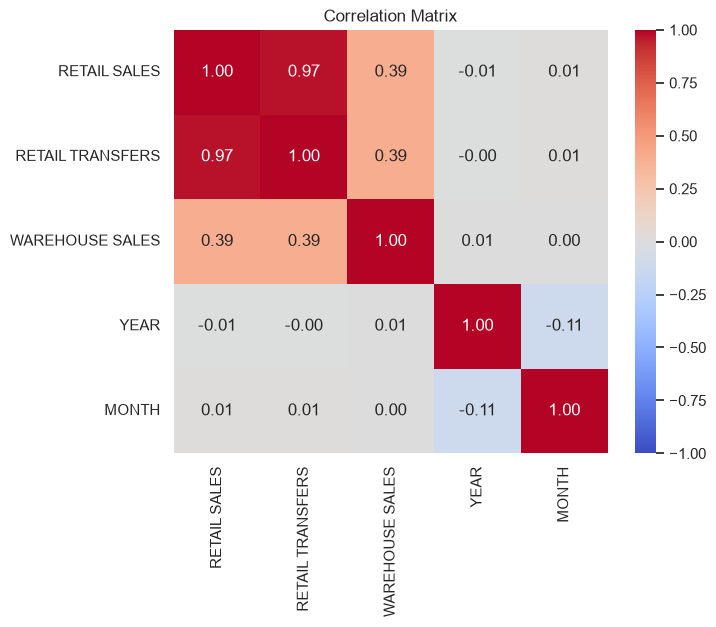

In [28]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

Retail sales and retail transfers have a correlation of 0.97, which is almost perfect: stores get restocked with about what they sell. Warehouse sales have a weaker link to retail sales (0.39), so bars and restaurants buy differently from store customers. YEAR and MONTH have almost no correlation with sales (close to 0).

## Conclusion

This dataset needed some cleaning before analysis. There were only a few missing values, and most of them were in rows that are not real products, so those rows were dropped. The normal IQR rule did not work well because 40% of the rows have zero sales, so I used the IQR rule on the log of sales instead. This removed only 122 extreme rows.

The main findings are:
1. Stores sell mostly liquor and wine, while the warehouse sells mostly beer to bars and restaurants.
2. Stores are restocked with about what they sell (correlation 0.97).
3. Sales are highest in December.
4. Most products sell very little, so the median is a better summary than the mean.